# Choosing one training target per identity

`Facial` maps **N frames of a person onto a single image**, so training it needs one target
image per identity. This notebook picks that frame.

Two things decide which frame is a good target:

1. **How well a recogniser identifies it.** The target is the best the reconstruction can
   ever be, so a mediocre target caps the whole model.
2. **Pose, consistently across identities.** `FacialAggregator` pools with a *fixed* learned
   query, so nothing tells the decoder which pose to produce. If the targets point in all
   directions the decoder can only learn their average, which is a blurry face.

Those two are nearly independent (measured: Spearman 0.09), so we use both: shortlist the
frames the recogniser identifies best, then take the most frontal one of those.

The ArcFace embedding norm, which the earlier notebook used, turns out to measure neither
— selecting on it is no better than picking a frame at random.

In [1]:
%load_ext autoreload
%autoreload 2

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pathlib import Path
from tqdm.auto import tqdm

from meles.detection import ARCFACE_TEMPLATE, default_detector, umeyama
from meles.embedding_aggregation import normalized
from meles.frame_embedder import FrameEmbedder, models

DATA_PATH = Path("../../data")
CORPUS = "voxceleb"  # "ytfaces" or "voxceleb"

# VoxCeleb2 holds 3.3M frames. Embedding all of them costs ~3.5 h and a ~10 GB parquet, and
# target selection does not need them: 64 frames spread over an identity's ~24 videos give a
# stable centroid and margin. SHORTLIST then keeps roughly the top quarter by margin either way
# -- YouTube Faces averages 195 frames per identity, so 50 there is the same fraction as 16 here.
SETTINGS = {
    "ytfaces": {"source": "ytfaces_all.parquet", "frames_per_identity": None, "shortlist": 50},
    "voxceleb": {"source": "voxceleb.parquet", "frames_per_identity": 64, "shortlist": 16},
}
SOURCE = SETTINGS[CORPUS]["source"]
FRAMES_PER_IDENTITY = SETTINGS[CORPUS]["frames_per_identity"]
SHORTLIST = SETTINGS[CORPUS]["shortlist"]

/data/projects/personal/meles/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
structure = pd.read_parquet(DATA_PATH / SOURCE)
structure

,identity,video,frame,frame_suffix,path
0,id06595,dcxzmpDDOgo,00017.0015.jpg,.jpg,voxceleb/id06595/dcxzmpDDOgo/00017.0015.jpg
1,id06595,dcxzmpDDOgo,00021.0022.jpg,.jpg,voxceleb/id06595/dcxzmpDDOgo/00021.0022.jpg
2,id06595,dcxzmpDDOgo,00010.0001.jpg,.jpg,voxceleb/id06595/dcxzmpDDOgo/00010.0001.jpg
3,id06595,dcxzmpDDOgo,00018.0016.jpg,.jpg,voxceleb/id06595/dcxzmpDDOgo/00018.0016.jpg
4,id06595,dcxzmpDDOgo,00018.0017.jpg,.jpg,voxceleb/id06595/dcxzmpDDOgo/00018.0017.jpg
...,...,...,...,...,...
3329031,id05692,IMlhY76Qz3g,00055.0015.jpg,.jpg,voxceleb/id05692/IMlhY76Qz3g/00055.0015.jpg
3329032,id05692,IMlhY76Qz3g,00054.0004.jpg,.jpg,voxceleb/id05692/IMlhY76Qz3g/00054.0004.jpg
3329033,id05692,IMlhY76Qz3g,00055.0022.jpg,.jpg,voxceleb/id05692/IMlhY76Qz3g/00055.0022.jpg
3329034,id05692,IMlhY76Qz3g,00055.0023.jpg,.jpg,voxceleb/id05692/IMlhY76Qz3g/00055.0023.jpg


In [3]:
from meles.dataset import truncate_dataset

MIN_VIDEOS_PER_IDENTITY = 2  # drop identities with fewer than this many videos
MAX_FRAMES_PER_VIDEO = 75  # keep only the first N frames of each video

# VoxCeleb2 arrives already truncated -- extract_video_frames capped it at 25 frames per video
# and every identity has at least 6 videos.
if CORPUS == "ytfaces":
    structure = truncate_dataset(structure, MIN_VIDEOS_PER_IDENTITY, MAX_FRAMES_PER_VIDEO)

if FRAMES_PER_IDENTITY is not None:
    # Shuffle before head(): taking the first N would draw them all from one video, and a
    # single video's frames are near duplicates, so the centroid would describe one sighting.
    structure = (
        structure.sample(frac=1, random_state=0)
        .groupby("identity", sort=False)
        .head(FRAMES_PER_IDENTITY)
        .sort_values(["identity", "video", "frame"])
        .reset_index(drop=True)
    )
structure

,identity,video,frame,frame_suffix,path
0,id00012,21Uxsk56VDQ,00002.0002.jpg,.jpg,voxceleb/id00012/21Uxsk56VDQ/00002.0002.jpg
1,id00012,21Uxsk56VDQ,00003.0005.jpg,.jpg,voxceleb/id00012/21Uxsk56VDQ/00003.0005.jpg
2,id00012,21Uxsk56VDQ,00011.0021.jpg,.jpg,voxceleb/id00012/21Uxsk56VDQ/00011.0021.jpg
3,id00012,2DLq_Kkc1r8,00016.0003.jpg,.jpg,voxceleb/id00012/2DLq_Kkc1r8/00016.0003.jpg
4,id00012,2DLq_Kkc1r8,00017.0010.jpg,.jpg,voxceleb/id00012/2DLq_Kkc1r8/00017.0010.jpg
...,...,...,...,...,...
367675,id09272,u7VNkYraCw0,00024.0010.jpg,.jpg,voxceleb/id09272/u7VNkYraCw0/00024.0010.jpg
367676,id09272,u7VNkYraCw0,00024.0011.jpg,.jpg,voxceleb/id09272/u7VNkYraCw0/00024.0011.jpg
367677,id09272,u7VNkYraCw0,00025.0013.jpg,.jpg,voxceleb/id09272/u7VNkYraCw0/00025.0013.jpg
367678,id09272,u7VNkYraCw0,00025.0014.jpg,.jpg,voxceleb/id09272/u7VNkYraCw0/00025.0014.jpg


## 1. Embed the sampled frames

One ArcFace embedding per frame, cached next to the dataset. The cache name carries the
per-identity cap, so a sampled run cannot overwrite a full one.

On YouTube Faces this is every frame (~20 min for 196k). On VoxCeleb2 it is 64 frames per
identity — 368k of 3.3M, about 25 min instead of 3.5 h.

In [4]:
# The cap is part of the name: a sampled cache must never be mistaken for the full one, which
# 08_voxceleb_download reads to calibrate its disjointness threshold.
EMBEDDINGS_PATH = DATA_PATH / (
    f"{CORPUS}_embeddings.parquet"
    if FRAMES_PER_IDENTITY is None
    else f"{CORPUS}_embeddings_{FRAMES_PER_IDENTITY}.parquet"
)

if EMBEDDINGS_PATH.exists():
    structure = pd.read_parquet(EMBEDDINGS_PATH)
else:
    arcface = FrameEmbedder(models.ARCFACE)
    structure["embedding"] = arcface.embed([str(DATA_PATH / path) for path in structure["path"]])
    structure.to_parquet(EMBEDDINGS_PATH, index=False)

# Unit vectors, so every comparison below is a plain cosine. Normalising matters: without it
# the long vectors dominate and we would be ranking by embedding norm again.
unit = np.asarray(normalized(np.stack(structure["embedding"].apply(np.asarray).values)), dtype=np.float32)
unit.shape

Embedding (ArcFace): 100%|██████████| 367680/367680 [22:46<00:00, 268.98frame/s]


(367680, 512)

## 2. How well is each frame identified?

Score every frame the way the experiment's classifier would, as a **margin**:

    margin = similarity to its own identity  -  similarity to the closest other identity

The "own identity" half is computed against that identity's **other videos only**.
Neighbouring frames of one shot are near-duplicates, so comparing a frame against its own
video would measure redundancy rather than identifiability — the same trap the fold split
exists to avoid.

In [5]:
identities = np.array(sorted(structure["identity"].unique()))
identity_of = structure["identity"].values
video_of = structure["video"].values

# The gallery an attacker would hold: one mean embedding per identity.
gallery = np.stack([unit[identity_of == name].mean(axis=0) for name in identities])
gallery /= np.linalg.norm(gallery, axis=1, keepdims=True)

# Genuine similarity, leaving the frame's own video out of its identity's centroid.
genuine = np.zeros(len(structure), dtype=np.float32)
for name in tqdm(identities, desc="genuine similarity"):
    rows = identity_of == name
    for video in np.unique(video_of[rows]):
        others = rows & (video_of != video)
        if not others.any():
            continue  # nothing to compare against; leaves genuine at 0, which sorts the frame last
        centroid = unit[others].mean(axis=0)
        held_out = rows & (video_of == video)
        genuine[held_out] = unit[held_out] @ (centroid / np.linalg.norm(centroid))

# Impostor similarity: the best match among all the other identities. Chunked, because the full
# frames-by-identities matrix is 8.5 GB on VoxCeleb2 (368k x 5,745) against 0.8 GB on YouTube Faces.
own = np.searchsorted(identities, identity_of)
impostor = np.empty(len(structure), dtype=np.float32)
for start in tqdm(range(0, len(structure), 20_000), desc="impostor similarity"):
    stop = min(start + 20_000, len(structure))
    block = unit[start:stop] @ gallery.T
    block[np.arange(stop - start), own[start:stop]] = -np.inf
    impostor[start:stop] = block.max(axis=1)

structure["margin"] = genuine - impostor
structure["margin"].describe()

impostor similarity: 100%|██████████| 19/19 [00:05<00:00,  3.42it/s]


count    367680.000000
mean          0.376011
std           0.165073
min          -0.908761
25%           0.313488
50%           0.410770
75%           0.484578
max           0.715324
Name: margin, dtype: float64

## 3. How frontal is each frame?

`umeyama` fits a **similarity** transform — rotation, uniform scale, translation — from the
five detected landmarks onto `ARCFACE_TEMPLATE`, which is the canonical *frontal* layout. A
similarity transform cannot represent out-of-plane rotation, so whatever error is left after
the best fit *is* the yaw and pitch. Lower is more frontal.

This needs a detection pass, so we only run it on the shortlist rather than every frame.

In [6]:
def frontality(landmarks):
    """RMS distance to the frontal template after the best similarity fit, in template pixels."""
    matrix = umeyama(landmarks, ARCFACE_TEMPLATE)
    aligned = landmarks @ matrix[:, :2].T + matrix[:, 2]
    return float(np.sqrt(((aligned - ARCFACE_TEMPLATE) ** 2).sum(axis=1).mean()))


# The frames the recogniser identifies best, per identity.
shortlist = structure.sort_values("margin", ascending=False).groupby("identity").head(SHORTLIST).copy()

residuals = []
for path in tqdm(shortlist["path"], desc="frontality"):
    area = default_detector.detect_best(cv2.imread(str(DATA_PATH / path)))
    # A frame without landmarks sorts last rather than being dropped.
    residuals.append(frontality(np.asarray(area.landmarks, dtype=np.float64))
                     if area is not None and area.landmarks is not None else np.inf)

shortlist["residual"] = residuals
shortlist["residual"].describe()

frontality: 100%|██████████| 91920/91920 [04:47<00:00, 319.47it/s]


count    91920.000000
mean         3.684589
std          1.415778
min          0.409499
25%          2.792913
50%          3.402513
75%          4.208592
max         16.929933
Name: residual, dtype: float64

## 4. Pick the target

The most frontal frame of each identity's shortlist.

In [7]:
targets = shortlist.loc[shortlist.groupby("identity")["residual"].idxmin()].reset_index(drop=True)

print(f"targets:            {len(targets):>8,}")
print(f"mean margin:        {targets['margin'].mean():>8.3f}   (all frames: {structure['margin'].mean():.3f})")
print(f"mean residual:      {targets['residual'].mean():>8.3f} px")
print(f"residual spread SD: {targets['residual'].std():>8.3f} px")

targets.drop(columns="embedding").head()

targets:               5,745
mean margin:           0.490   (all frames: 0.376)
mean residual:         2.129 px
residual spread SD:    0.572 px


,identity,video,frame,frame_suffix,path,margin,residual
0,id00012,s7MiVWybRhg,00148.0001.jpg,.jpg,voxceleb/id00012/s7MiVWybRhg/00148.0001.jpg,0.476193,2.132663
1,id00015,a4NsaA5dv04,00283.0008.jpg,.jpg,voxceleb/id00015/a4NsaA5dv04/00283.0008.jpg,0.486861,2.212762
2,id00016,TufzL0Yj-HA,00087.0021.jpg,.jpg,voxceleb/id00016/TufzL0Yj-HA/00087.0021.jpg,0.554282,2.168729
3,id00018,Y2uMIwUnWGw,00093.0018.jpg,.jpg,voxceleb/id00018/Y2uMIwUnWGw/00093.0018.jpg,0.482267,2.057234
4,id00019,L8Qipe2IKjg,00033.0006.jpg,.jpg,voxceleb/id00019/L8Qipe2IKjg/00033.0006.jpg,0.546507,2.081730


Both numbers should have moved the right way: a higher margin than the dataset average means
the targets are easier to identify, and a small residual spread means they share a pose.

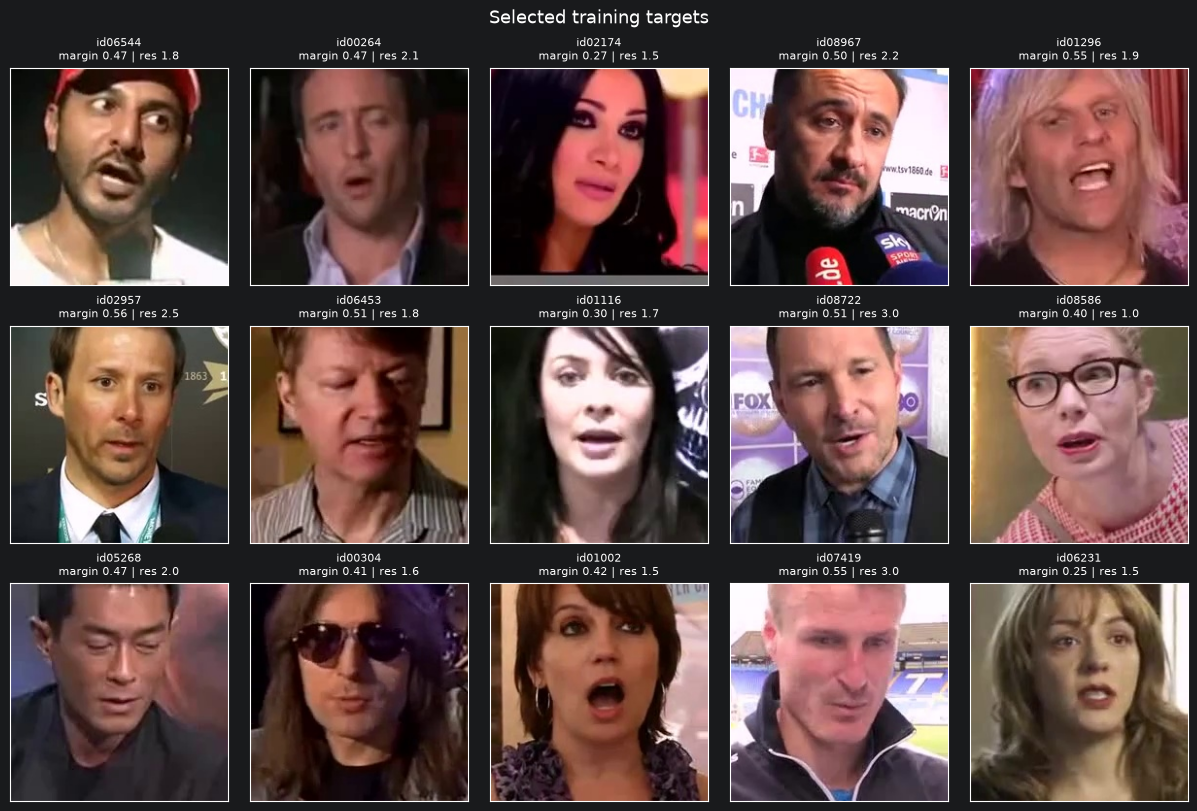

In [8]:
N_SHOWN = 15

sample = targets.sample(n=N_SHOWN, random_state=1)

fig, axes = plt.subplots(3, 5, figsize=(12, 8), layout="constrained")
for ax, (_, target) in zip(axes.flat, sample.iterrows()):
    ax.imshow(cv2.cvtColor(cv2.imread(str(DATA_PATH / target["path"])), cv2.COLOR_BGR2RGB))
    ax.set_title(f"{target['identity'].replace('_', ' ')}\nmargin {target['margin']:.2f} | res {target['residual']:.1f}",
                 fontsize=8)
    ax.set_xticks([])
    ax.set_yticks([])

fig.suptitle("Selected training targets", fontsize=13)
plt.show()

## 5. Save

One row per identity, pointing at the frame to use as that identity's target.

In [9]:
targets.drop(columns="embedding").to_parquet(DATA_PATH / f"{CORPUS}_targets.parquet", index=False)
print(f"wrote {CORPUS}_targets.parquet: {len(targets):,} targets")

wrote voxceleb_targets.parquet: 5,745 targets


In [10]:
# YouTube Faces only. 'ytfaces_wide.parquet' is the structure 06_facial trains on, rebuilt here
# because the margin pass is what truncated it. VoxCeleb2 needs no equivalent: 'voxceleb.parquet'
# already holds every frame, and this run only ever saw a 64-frame sample of each identity.
if CORPUS == "ytfaces":
    structure.to_parquet(DATA_PATH / "ytfaces_values.parquet", index=False)

    # It cannot be written back to 'ytfaces.parquet' -- workflow/config.yaml names that file as
    # the Snakemake dataset, so widening it in place would silently redefine the sweep's identities.
    structure.drop(columns=[c for c in ("embedding", "margin") if c in structure]).to_parquet(
        DATA_PATH / "ytfaces_wide.parquet", index=False
    )
else:
    print(f"{CORPUS}: nothing else to write; voxceleb.parquet is already the training structure")

voxceleb: nothing else to write; voxceleb.parquet is already the training structure
